In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8')
plt.rcParams['figure.figsize'] = (12, 6)

In [11]:
import sys
print(sys.version)

3.9.9 (tags/v3.9.9:ccb0e6a, Nov 15 2021, 18:08:50) [MSC v.1929 64 bit (AMD64)]


In [12]:
# Загрузка датасета
df = pd.read_parquet('../data/raw/cic-collection.parquet')
print(f"Размер датасета: {df.shape[0]:,} строк × {df.shape[1]} столбцов")

Размер датасета: 9,167,581 строк × 59 столбцов


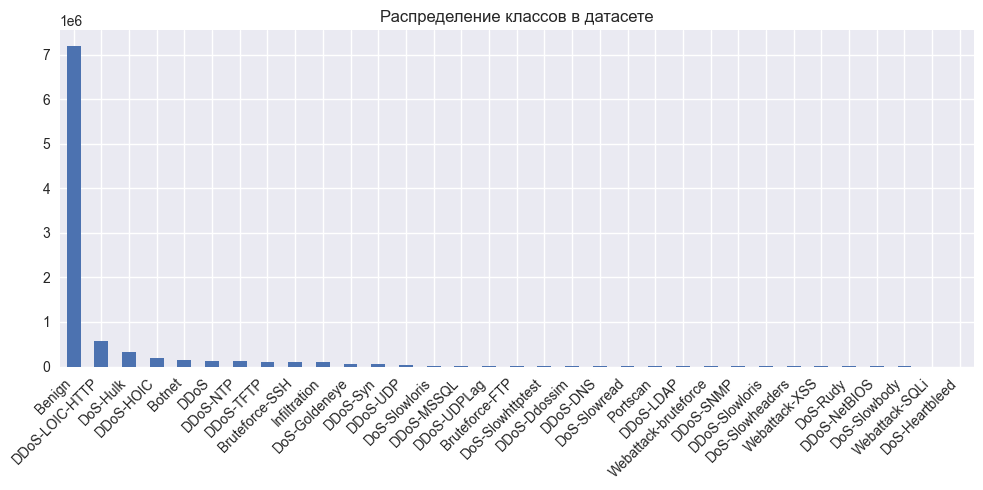

In [13]:
# Анализ целевой переменной
plt.figure(figsize=(10, 5))
df['Label'].value_counts().plot(kind='bar')
plt.title('Распределение классов в датасете')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../results/label_distribution.png', dpi=300)
plt.show()

In [14]:
# Статистики числовых признаков
df.describe().to_csv('../results/feature_statistics.csv')
df.describe()

,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Mean,...,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06,...,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06,9.167581e+06
mean,1.590669e+07,4.079505e+01,9.505221e+00,2.063825e+03,1.001084e+04,2.946960e+02,8.127664e+01,1.043248e+02,6.070652e+02,2.002887e+02,...,3.634311e+01,-1.071509e+06,1.167681e+05,5.520761e+04,1.930339e+05,8.280822e+04,8.015305e+06,5.491758e+05,8.775097e+06,7.413580e+06
std,6.569715e+08,2.066283e+03,5.805652e+02,8.358580e+04,1.281297e+06,5.018536e+02,1.422410e+02,1.989876e+02,1.180525e+03,3.792937e+02,...,2.053093e+03,3.372568e+07,1.476691e+06,8.546709e+05,1.981935e+06,1.272038e+06,3.503701e+08,2.251440e+08,8.321556e+08,8.463088e+07
min,-9.190110e+11,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,-1.408238e+09,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.160100e+04,2.000000e+00,1.000000e+00,2.900000e+01,0.000000e+00,2.000000e+01,7.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,3.966860e+05,3.000000e+00,2.000000e+00,9.700000e+01,2.320000e+02,5.500000e+01,4.400000e+01,1.154701e+01,1.520000e+02,1.080000e+02,...,1.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,5.562333e+06,7.000000e+00,5.000000e+00,9.350000e+02,9.640000e+02,5.070000e+02,1.076667e+02,1.807106e+02,9.640000e+02,2.163750e+02,...,4.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,1.200000e+08,3.096290e+05,2.919220e+05,1.443918e+08,6.554530e+08,6.444000e+04,1.652931e+04,1.840158e+04,6.516000e+04,3.387929e+04,...,3.096280e+05,6.724045e+07,1.140000e+08,7.495335e+07,1.140000e+08,1.140000e+08,3.955714e+11,2.622479e+11,9.797810e+11,2.399340e+11


In [15]:
# Проверка пропущенных значений
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Пропуски': missing, 'Процент': missing_pct})
missing_df[missing_df['Пропуски'] > 0].to_csv('../results/missing_values.csv')
missing_df[missing_df['Пропуски'] > 0]

,Пропуски,Процент


In [2]:
# Ячейка 1: Загрузка датасета и просмотр колонок
import pandas as pd
import numpy as np

print("📥 Загрузка датасета CIC-IDS-Collection...")

# Загрузка датасета (укажите правильный путь к вашему файлу)
df = pd.read_parquet('../data/raw/cic-collection.parquet')
# ИЛИ если у вас CSV:
# df = pd.read_csv('../data/raw/cic-collection.csv')

print("✅ Датасет загружен!")
print("=" * 80)
print("📋 ВСЕ НАЗВАНИЯ КОЛОНОК В ДАТАСЕТЕ")
print("=" * 80)

for i, col in enumerate(df.columns, 1):
    print(f"{i:3d}. {col}")

print("=" * 80)
print(f"Всего колонок: {len(df.columns)}")
print(f"Всего записей: {len(df):,}")
print("=" * 80)

# Дополнительно: типы данных
print("\n📊 ТИПЫ ДАННЫХ:")
print(df.dtypes)

📥 Загрузка датасета CIC-IDS-Collection...
✅ Датасет загружен!
📋 ВСЕ НАЗВАНИЯ КОЛОНОК В ДАТАСЕТЕ
  1. Flow Duration
  2. Total Fwd Packets
  3. Total Backward Packets
  4. Fwd Packets Length Total
  5. Bwd Packets Length Total
  6. Fwd Packet Length Max
  7. Fwd Packet Length Mean
  8. Fwd Packet Length Std
  9. Bwd Packet Length Max
 10. Bwd Packet Length Mean
 11. Bwd Packet Length Std
 12. Flow Bytes/s
 13. Flow Packets/s
 14. Flow IAT Mean
 15. Flow IAT Std
 16. Flow IAT Max
 17. Flow IAT Min
 18. Fwd IAT Total
 19. Fwd IAT Mean
 20. Fwd IAT Std
 21. Fwd IAT Max
 22. Fwd IAT Min
 23. Bwd IAT Total
 24. Bwd IAT Mean
 25. Bwd IAT Std
 26. Bwd IAT Max
 27. Bwd IAT Min
 28. Fwd PSH Flags
 29. Fwd Header Length
 30. Bwd Header Length
 31. Fwd Packets/s
 32. Bwd Packets/s
 33. Packet Length Max
 34. Packet Length Mean
 35. Packet Length Std
 36. Packet Length Variance
 37. SYN Flag Count
 38. URG Flag Count
 39. Avg Packet Size
 40. Avg Fwd Segment Size
 41. Avg Bwd Segment Size
 42. Subf